In [1]:
install.packages("igraph", repos = "https://cloud.r-project.org")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [2]:
library(igraph)


Attaching package: ‘igraph’


The following objects are masked from ‘package:stats’:

    decompose, spectrum


The following object is masked from ‘package:base’:

    union




In [3]:
g <- graph(
  c(1,2, 2,3, 3,4, 4,1),
  directed = FALSE,
  n = 7
)

print(g)

Warning message:
“`graph()` was deprecated in igraph 2.1.0.
ℹ Please use `make_graph()` instead.”


IGRAPH b8ba820 U--- 7 4 -- 
+ edges from b8ba820:
[1] 1--2 2--3 3--4 1--4


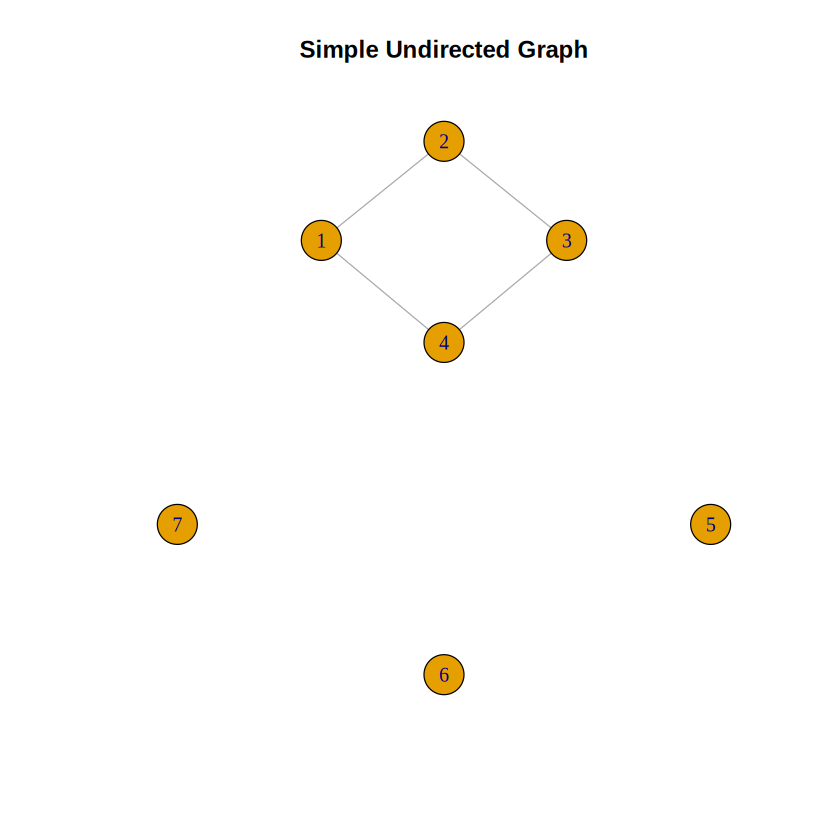

In [4]:
plot(
  g,
  main = "Simple Undirected Graph"
)

In [5]:
g1 <- graph(
  c(
    "Amy", "Ram",
    "Ram", "Li",
    "Li", "Amy",
    "Amy", "Li",
    "Kate", "Li"
  ),
  directed = TRUE
)

print(g1)

IGRAPH 4dfecbe DN-- 4 5 -- 
+ attr: name (v/c)
+ edges from 4dfecbe (vertex names):
[1] Amy ->Ram Ram ->Li  Li  ->Amy Amy ->Li  Kate->Li 


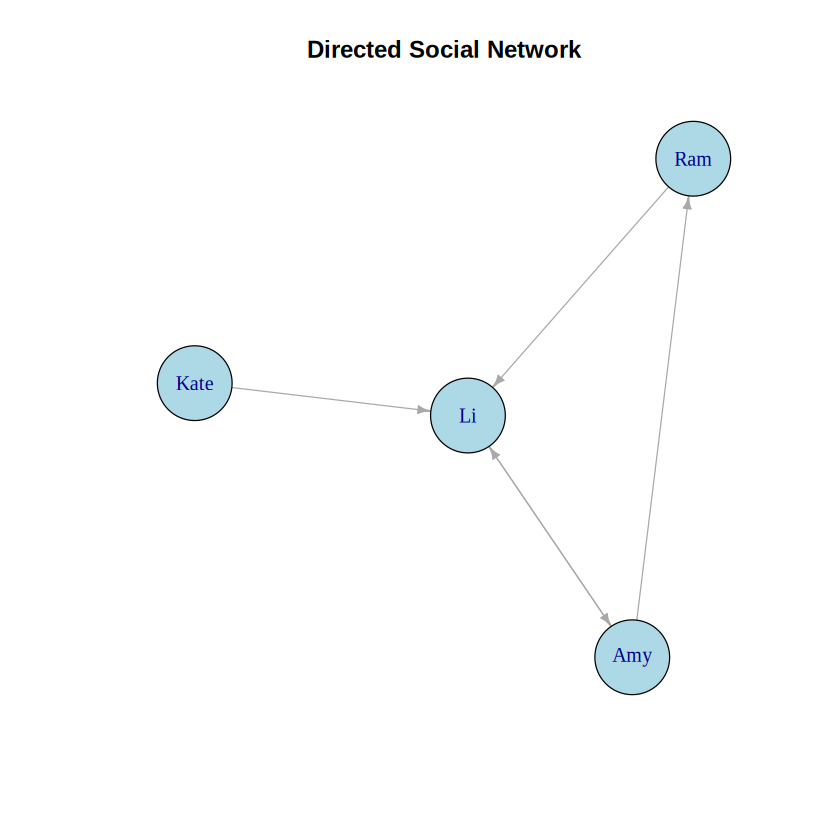

In [6]:
plot(
  g1,
  main = "Directed Social Network",
  vertex.color = "lightblue",
  vertex.size = 30,
  edge.arrow.size = 0.5
)

In [7]:
degree(g1, mode = "all")

Amy  Ram   Li Kate 
   3    2    4    1

In [8]:
degree(g1, mode = "in")

Amy  Ram   Li Kate 
   1    1    3    0

In [9]:
diameter(
  g1,
  directed = FALSE,
  weights = NA
)

[1] 2

In [10]:
edge_density(
  g1,
  loops = FALSE
)

[1] 0.4166667

In [11]:
reciprocity(g1)

[1] 0.4

In [12]:
closeness(
  g1,
  mode = "all",
  weights = NA
)

Amy       Ram        Li      Kate 
0.2500000 0.2500000 0.3333333 0.2000000

In [13]:
betweenness(
  g1,
  directed = TRUE,
  weights = NA
)

Amy  Ram   Li Kate 
   2    0    3    0

In [14]:
edge_betweenness(
  g1,
  directed = TRUE,
  weights = NA
)

[1] 3 2 5 1 3

In [15]:
# Dataset: Zachary's Karate Club (34 members, 78 friendships)
# Built into igraph, so no external download is needed.
karate <- make_graph("Zachary")

data <- as_data_frame(karate, what = "edges")
data <- data.frame(
  first  = paste0("M", data$from),
  second = paste0("M", data$to)
)

write.csv(data, "networkdata.csv", row.names = FALSE)

data <- read.csv(
  "networkdata.csv",
  header = TRUE
)

head(data)

,first,second
,<chr>,<chr>
1,M1,M2
2,M1,M3
3,M1,M4
4,M1,M5
5,M1,M6
6,M1,M7


In [16]:
y <- data.frame(
  data$first,
  data$second
)

head(y)

,data.first,data.second
,<chr>,<chr>
1,M1,M2
2,M1,M3
3,M1,M4
4,M1,M5
5,M1,M6
6,M1,M7


In [17]:
net <- graph_from_data_frame(
  y,
  directed = TRUE
)

print(net)

IGRAPH cb9ed3f DN-- 34 78 -- 
+ attr: name (v/c)
+ edges from cb9ed3f (vertex names):
 [1] M1 ->M2  M1 ->M3  M1 ->M4  M1 ->M5  M1 ->M6  M1 ->M7  M1 ->M8  M1 ->M9 
 [9] M1 ->M11 M1 ->M12 M1 ->M13 M1 ->M14 M1 ->M18 M1 ->M20 M1 ->M22 M1 ->M32
[17] M2 ->M3  M2 ->M4  M2 ->M8  M2 ->M14 M2 ->M18 M2 ->M20 M2 ->M22 M2 ->M31
[25] M3 ->M4  M3 ->M8  M3 ->M28 M3 ->M29 M3 ->M33 M3 ->M10 M3 ->M9  M3 ->M14
[33] M4 ->M8  M4 ->M13 M4 ->M14 M5 ->M7  M5 ->M11 M6 ->M7  M6 ->M11 M6 ->M17
[41] M7 ->M17 M9 ->M31 M9 ->M33 M9 ->M34 M10->M34 M14->M34 M15->M33 M15->M34
[49] M16->M33 M16->M34 M19->M33 M19->M34 M20->M34 M21->M33 M21->M34 M23->M33
[57] M23->M34 M24->M26 M24->M28 M24->M33 M24->M34 M24->M30 M25->M26 M25->M28
+ ... omitted several edges


In [18]:
V(net)$label <- V(net)$name

V(net)$label

[1] "M1"  "M2"  "M3"  "M4"  "M5"  "M6"  "M7"  "M9"  "M10" "M14" "M15" "M16"
[13] "M19" "M20" "M21" "M23" "M24" "M25" "M26" "M27" "M28" "M29" "M30" "M31"
[25] "M32" "M33" "M8"  "M11" "M12" "M13" "M18" "M22" "M17" "M34"

In [19]:
V(net)$degree <- degree(net)

V(net)$degree

[1] 16  9 10  6  3  4  4  5  2  5  2  2  2  3  2  2  5  3  3  2  4  3  4  4  6
[26] 12  4  3  1  2  2  2  2 17

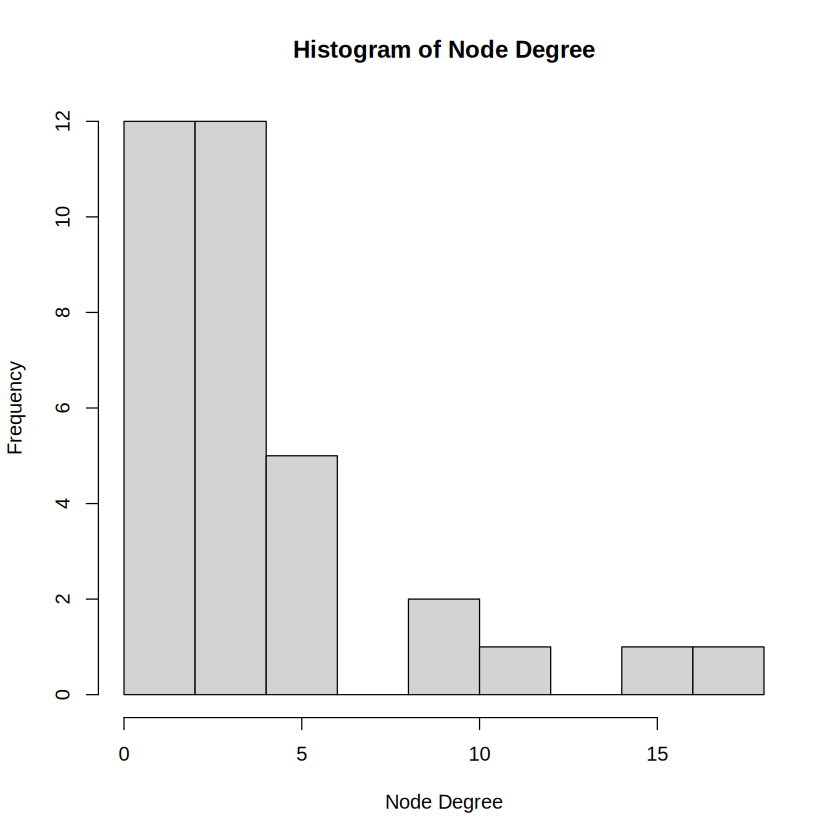

In [20]:
hist(
  V(net)$degree,
  main = "Histogram of Node Degree",
  xlab = "Node Degree",
  ylab = "Frequency"
)

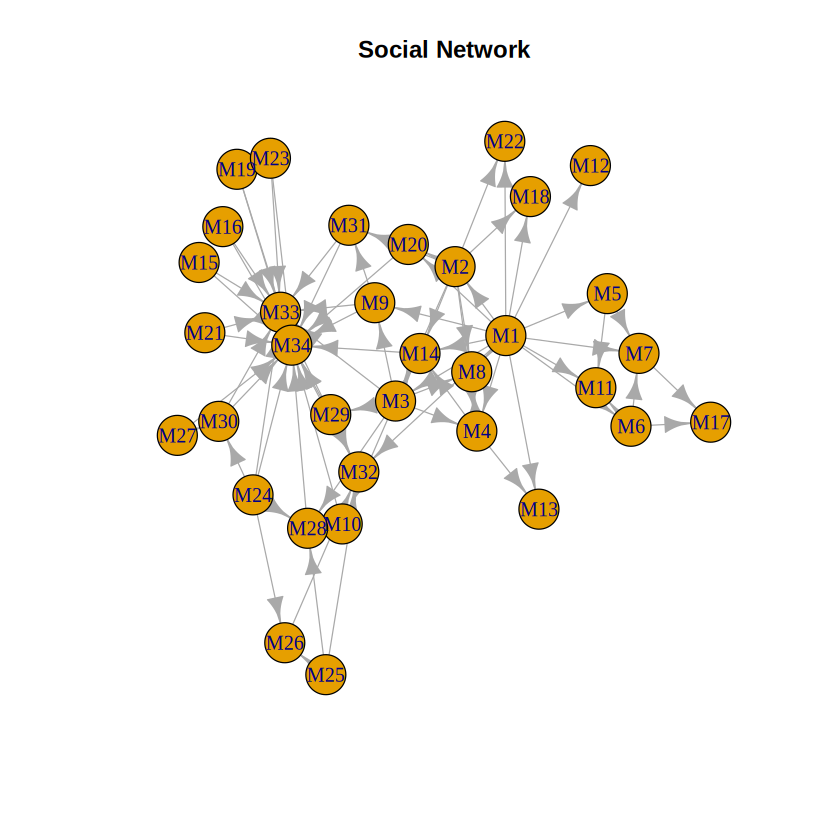

In [21]:
plot(
  net,
  main = "Social Network"
)

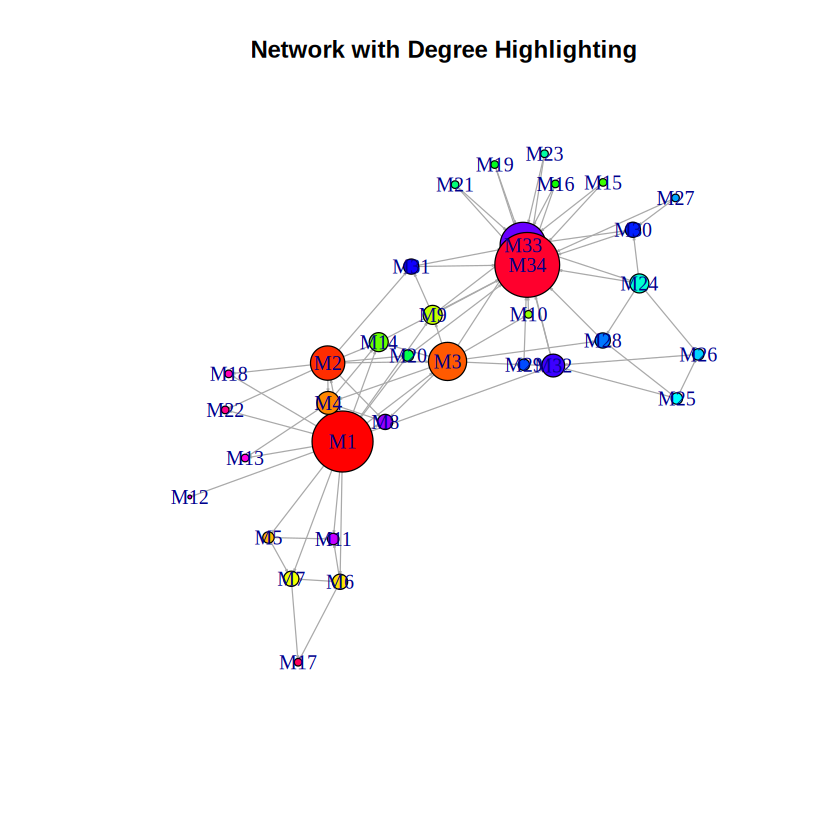

In [22]:
set.seed(123)

plot(
  net,
  vertex.color = rainbow(vcount(net)),
  vertex.size = V(net)$degree * 1.5,
  edge.arrow.size = 0.1,
  layout = layout_with_fr(net),
  main = "Network with Degree Highlighting"
)

In [23]:
hs <- hub_score(net)$vector

hs

Warning message:
“`hub_score()` was deprecated in igraph 2.0.3.
ℹ Please use `hits_scores()` instead.”


M1          M2          M3          M4          M5          M6 
1.000000000 0.618926327 0.879108545 0.263193821 0.092175000 0.096050837 
         M7          M9         M10         M14         M15         M16 
0.003875838 0.842006694 0.437432488 0.437432488 0.785341750 0.785341750 
        M19         M20         M21         M23         M24         M25 
0.785341750 0.437432488 0.785341750 0.785341750 0.965931628 0.192497843 
        M26         M27         M28         M29         M30         M31 
0.068536432 0.494060956 0.437432488 0.505968920 0.785341750 0.785341750 
        M32         M33          M8         M11         M12         M13 
0.785341750 0.437432488 0.000000000 0.000000000 0.000000000 0.000000000 
        M18         M22         M17         M34 
0.000000000 0.000000000 0.000000000 0.000000000

In [24]:
as <- authority_score(net)$vector

as

Warning message:
“`authority_score()` was deprecated in igraph 2.1.0.
ℹ Please use `hits_scores()` instead.”


M1          M2          M3          M4          M5          M6 
0.000000000 0.088669268 0.143549012 0.221498923 0.088669268 0.088669268 
         M7          M9         M10         M14         M15         M16 
0.105359115 0.166619179 0.077949911 0.244836126 0.000000000 0.000000000 
        M19         M20         M21         M23         M24         M25 
0.000000000 0.143549012 0.000000000 0.000000000 0.000000000 0.000000000 
        M26         M27         M28         M29         M30         M31 
0.102717093 0.000000000 0.180667004 0.077949911 0.129456473 0.129539861 
        M32         M33          M8         M11         M12         M13 
0.156678879 0.795343902 0.244836126 0.105359115 0.088669268 0.112006471 
        M18         M22         M17         M34 
0.143549012 0.143549012 0.008860425 1.000000000

In [25]:
hub_scores <- data.frame(
  Node = V(net)$name,
  Hub_Score = hs
)

hub_scores

,Node,Hub_Score
,<chr>,<dbl>
M1,M1,1.000000000
M2,M2,0.618926327
M3,M3,0.879108545
M4,M4,0.263193821
M5,M5,0.092175000
M6,M6,0.096050837
M7,M7,0.003875838
M9,M9,0.842006694
M10,M10,0.437432488


In [27]:
authority_scores <- data.frame(
  Node = V(net)$name,
  Authority_Score = as
)

authority_scores

,Node,Authority_Score
,<chr>,<dbl>
M1,M1,0.000000000
M2,M2,0.088669268
M3,M3,0.143549012
M4,M4,0.221498923
M5,M5,0.088669268
M6,M6,0.088669268
M7,M7,0.105359115
M9,M9,0.166619179
M10,M10,0.077949911


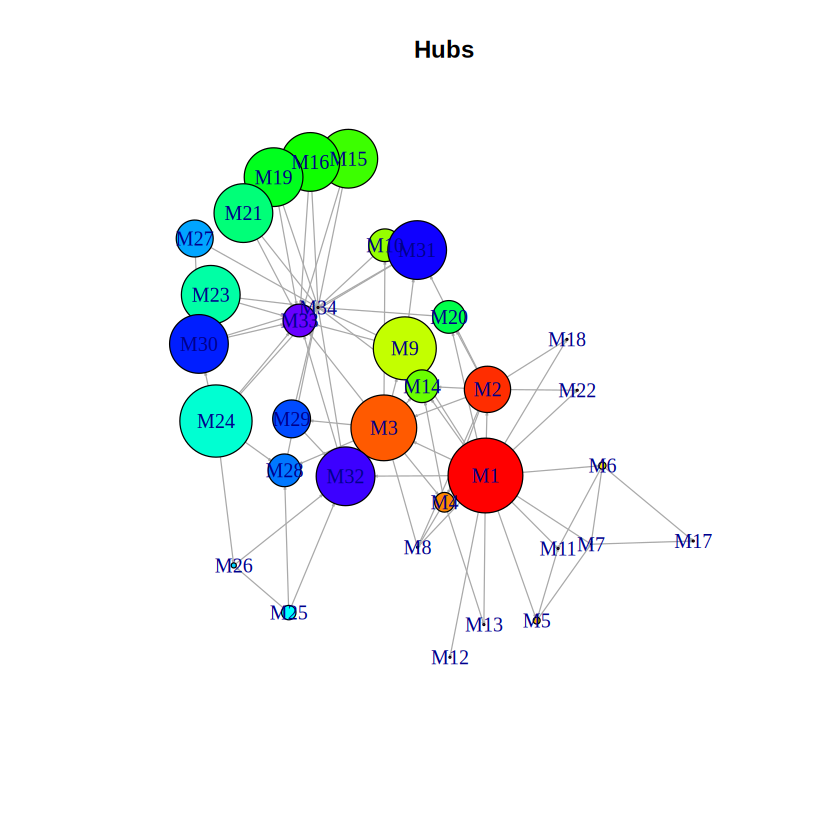

In [26]:
set.seed(123)

plot(
  net,
  vertex.size = hs * 30,
  main = "Hubs",
  vertex.color = rainbow(vcount(net)),
  edge.arrow.size = 0.1,
  layout = layout_with_kk(net)
)

In [ ]:
set.seed(123)

plot(
  net,
  vertex.size = as * 30,
  main = "Authorities",
  vertex.color = rainbow(vcount(net)),
  edge.arrow.size = 0.1,
  layout = layout_with_kk(net)
)

In [31]:
net_undirected <- graph_from_data_frame(
  y,
  directed = FALSE
)

print(net_undirected)

IGRAPH c9c7737 UN-- 34 78 -- 
+ attr: name (v/c)
+ edges from c9c7737 (vertex names):
 [1] M1 --M2  M1 --M3  M1 --M4  M1 --M5  M1 --M6  M1 --M7  M1 --M8  M1 --M9 
 [9] M1 --M11 M1 --M12 M1 --M13 M1 --M14 M1 --M18 M1 --M20 M1 --M22 M1 --M32
[17] M2 --M3  M2 --M4  M2 --M8  M2 --M14 M2 --M18 M2 --M20 M2 --M22 M2 --M31
[25] M3 --M4  M3 --M8  M3 --M28 M3 --M29 M3 --M33 M3 --M10 M3 --M9  M3 --M14
[33] M4 --M8  M4 --M13 M4 --M14 M5 --M7  M5 --M11 M6 --M7  M6 --M11 M6 --M17
[41] M7 --M17 M9 --M31 M9 --M33 M9 --M34 M10--M34 M14--M34 M15--M33 M15--M34
[49] M16--M33 M16--M34 M19--M33 M19--M34 M20--M34 M21--M33 M21--M34 M23--M33
[57] M23--M34 M24--M26 M24--M28 M24--M33 M24--M34 M24--M30 M25--M26 M25--M28
+ ... omitted several edges


In [32]:
cnet <- cluster_edge_betweenness(
  net_undirected
)

print(cnet)

IGRAPH clustering edge betweenness, groups: 5, mod: 0.4
+ groups:
  $`1`
   [1] "M1"  "M2"  "M4"  "M14" "M20" "M8"  "M12" "M13" "M18" "M22"
  
  $`2`
  [1] "M3"  "M25" "M26" "M28" "M29" "M32"
  
  $`3`
  [1] "M5"  "M6"  "M7"  "M11" "M17"
  
  $`4`
  + ... omitted several groups/vertices


In [33]:
membership(cnet)

 M1  M2  M3  M4  M5  M6  M7  M9 M10 M14 M15 M16 M19 M20 M21 M23 M24 M25 M26 M27 
  1   1   2   1   3   3   3   4   5   1   4   4   4   1   4   4   4   2   2   4 
M28 M29 M30 M31 M32 M33  M8 M11 M12 M13 M18 M22 M17 M34 
  2   2   4   4   2   4   1   3   1   1   1   1   3   4 

In [34]:
length(cnet)

[1] 5

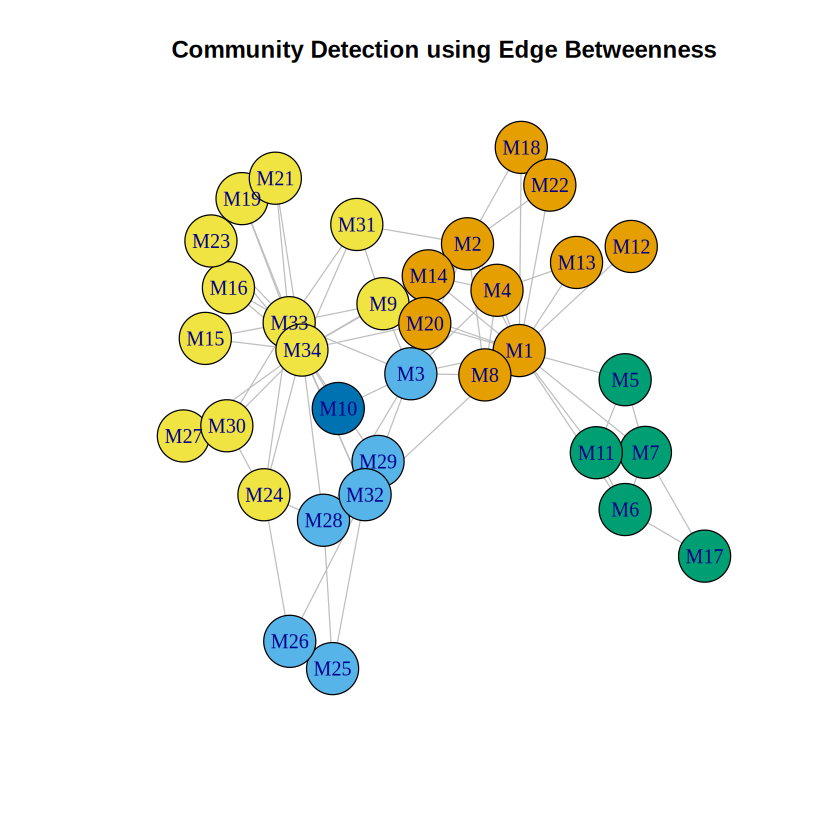

In [35]:
plot(
  net_undirected,
  vertex.color = membership(cnet),
  vertex.size = 20,
  vertex.label = V(net_undirected)$name,
  edge.color = "gray",
  main = "Community Detection using Edge Betweenness"
)

In [36]:
communities <- split(
  V(net_undirected)$name,
  membership(cnet)
)

communities

$`1`
 [1] "M1"  "M2"  "M4"  "M14" "M20" "M8"  "M12" "M13" "M18" "M22"

$`2`
[1] "M3"  "M25" "M26" "M28" "M29" "M32"

$`3`
[1] "M5"  "M6"  "M7"  "M11" "M17"

$`4`
 [1] "M9"  "M15" "M16" "M19" "M21" "M23" "M24" "M27" "M30" "M31" "M33" "M34"

$`5`
[1] "M10"